# Package Import

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import seaborn as sns

# File Import

In [2]:
df = pd.read_csv(r'C:\Users\vijay\Documents\Git\stratascratch_doordash_delivery_times\historical_data.csv')
df.describe()

,market_id,store_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration
count,196441.000000,197428.000000,196433.000000,197428.000000,197428.000000,197428.000000,197428.000000,197428.000000,181166.000000,181166.000000,181166.000000,197428.000000,196902.000000
mean,2.978706,3530.510272,2.882352,3.196391,2682.331402,2.670791,686.218470,1159.588630,44.808093,41.739747,58.050065,308.560179,545.358935
std,1.524867,2053.496711,1.503771,2.666546,1823.093688,1.630255,522.038648,558.411377,34.526783,32.145733,52.661830,90.139653,219.352902
min,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,-86.000000,0.000000,-4.000000,-5.000000,-6.000000,0.000000,0.000000
25%,2.000000,1686.000000,1.000000,2.000000,1400.000000,1.000000,299.000000,800.000000,17.000000,15.000000,17.000000,251.000000,382.000000
50%,3.000000,3592.000000,3.000000,3.000000,2200.000000,2.000000,595.000000,1095.000000,37.000000,34.000000,41.000000,251.000000,544.000000
75%,4.000000,5299.000000,4.000000,4.000000,3395.000000,3.000000,949.000000,1395.000000,65.000000,62.000000,85.000000,446.000000,702.000000
max,6.000000,6987.000000,7.000000,411.000000,27100.000000,20.000000,14700.000000,14700.000000,171.000000,154.000000,285.000000,2715.000000,2088.000000


In [3]:
np.random.seed(22)

df["created_at"] = pd.to_datetime(df["created_at"])
df["actual_delivery_time"] = pd.to_datetime(df["actual_delivery_time"])
df.dtypes

market_id                                              float64
created_at                                      datetime64[us]
actual_delivery_time                            datetime64[us]
store_id                                                 int64
store_primary_category                                     str
order_protocol                                         float64
total_items                                              int64
subtotal                                                 int64
num_distinct_items                                       int64
min_item_price                                           int64
max_item_price                                           int64
total_onshift_dashers                                  float64
total_busy_dashers                                     float64
total_outstanding_orders                               float64
estimated_order_place_duration                           int64
estimated_store_to_consumer_driving_duration           

In [4]:
# Calculating delivery duration in seconds

df["delivery_duration"] = df["actual_delivery_time"] - df["created_at"]
df["delivery_duration"] = df["delivery_duration"].dt.total_seconds()

# Dropping records where created at and delivery date are not the same day
df = df[df["created_at"].dt.date == df["actual_delivery_time"].dt.date]
df.describe()

,market_id,created_at,actual_delivery_time,store_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_order_place_duration,estimated_store_to_consumer_driving_duration,delivery_duration
count,190494.000000,191456,191456,191456.000000,190489.000000,191456.000000,191456.000000,191456.000000,191456.000000,191456.000000,175670.000000,175670.000000,175670.000000,191456.000000,190933.000000,191456.000000
mean,2.981123,2015-02-04 22:20:07.141990,2015-02-04 23:07:42.012138,3529.154573,2.880487,3.201101,2691.468285,2.675884,686.894054,1161.777975,45.597985,42.456287,59.246826,308.589389,544.358199,2854.870148
min,1.000000,2015-01-21 15:22:03,2015-01-21 15:58:11,1.000000,1.000000,1.000000,0.000000,1.000000,-86.000000,0.000000,-4.000000,-5.000000,-6.000000,0.000000,0.000000,101.000000
25%,2.000000,2015-01-29 02:41:40.500000,2015-01-29 03:30:53.750000,1686.000000,1.000000,2.000000,1412.000000,1.000000,299.000000,800.000000,18.000000,16.000000,18.000000,251.000000,381.000000,2103.000000
50%,3.000000,2015-02-05 03:45:41,2015-02-05 04:57:57.500000,3591.000000,3.000000,3.000000,2213.500000,2.000000,595.000000,1095.000000,38.000000,36.000000,43.000000,251.000000,542.000000,2659.000000
75%,4.000000,2015-02-12 01:48:05.500000,2015-02-12 02:34:02.250000,5296.000000,4.000000,4.000000,3400.000000,3.000000,949.000000,1395.000000,67.000000,63.000000,87.000000,446.000000,701.000000,3377.000000
max,6.000000,2015-02-18 06:00:44,2015-02-18 07:35:20,6987.000000,7.000000,411.000000,27100.000000,20.000000,14700.000000,14700.000000,171.000000,154.000000,285.000000,2715.000000,2088.000000,57032.000000
std,1.524516,NaN,NaN,2053.128030,1.504391,2.672747,1827.108288,1.632850,520.816515,557.417612,34.673107,32.255219,52.961864,90.179896,219.182052,1132.415062


In [5]:
# Understanding missing values in the dataset
for i in df.columns:
  print(i, df[i].isna().sum())

market_id 962
created_at 0
actual_delivery_time 0
store_id 0
store_primary_category 4621
order_protocol 967
total_items 0
subtotal 0
num_distinct_items 0
min_item_price 0
max_item_price 0
total_onshift_dashers 15786
total_busy_dashers 15786
total_outstanding_orders 15786
estimated_order_place_duration 0
estimated_store_to_consumer_driving_duration 523
delivery_duration 0


In [6]:
# removing rows where target variable is missing
df = df[-df["delivery_duration"].isna()]

# fill missing values in store_primary_category with 'Unknown'
df["store_primary_category"] = df["store_primary_category"].fillna('Unknown')

# EDA

In [7]:
import math
import plotly.subplots as sp
import plotly.graph_objects as go

# create a grid of histograms for all columns in the dataframe
cols = df.columns
n = len(cols)
ncols = 4  # Number of columns in the grid
nrows = math.ceil(n / ncols)

fig = sp.make_subplots(rows=nrows, cols=ncols, subplot_titles=cols)

for i, col in enumerate(cols):
    row = i // ncols + 1
    col_pos = i % ncols + 1
    fig.add_trace(
        go.Histogram(x=df[col], name=col, nbinsx=30, marker=dict(color='#1f77b4', line=dict(width=1))),
        row=row, col=col_pos
    )

fig.update_layout(
    height=500 * nrows,
    width=550 * ncols,
    showlegend=False,
    title_text="Grid of Histograms"
)
fig.show()

<Axes: >

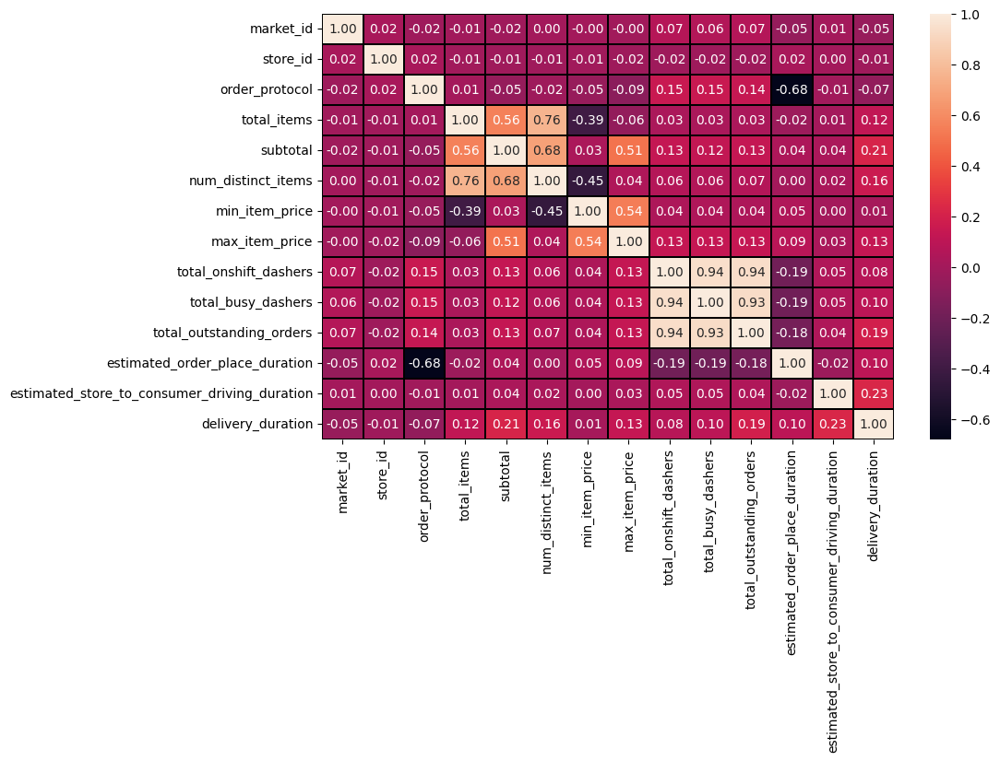

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

corr_plot = sns.heatmap(
              df.corr(numeric_only=True),
              linewidths=0.1,
              linecolor='black',
              annot=True,
              fmt=".2f",
  )
display(corr_plot)

Some columns are heavily correlated
- Order protocol and estimated order duration. Let's keep order protocol
- Total items and number of distinct items and subtotal. Let's keep total items.
- total outstanding orders, total on shift dashers and total busy dashers. Let's keep total outstanding orders

<Axes: >

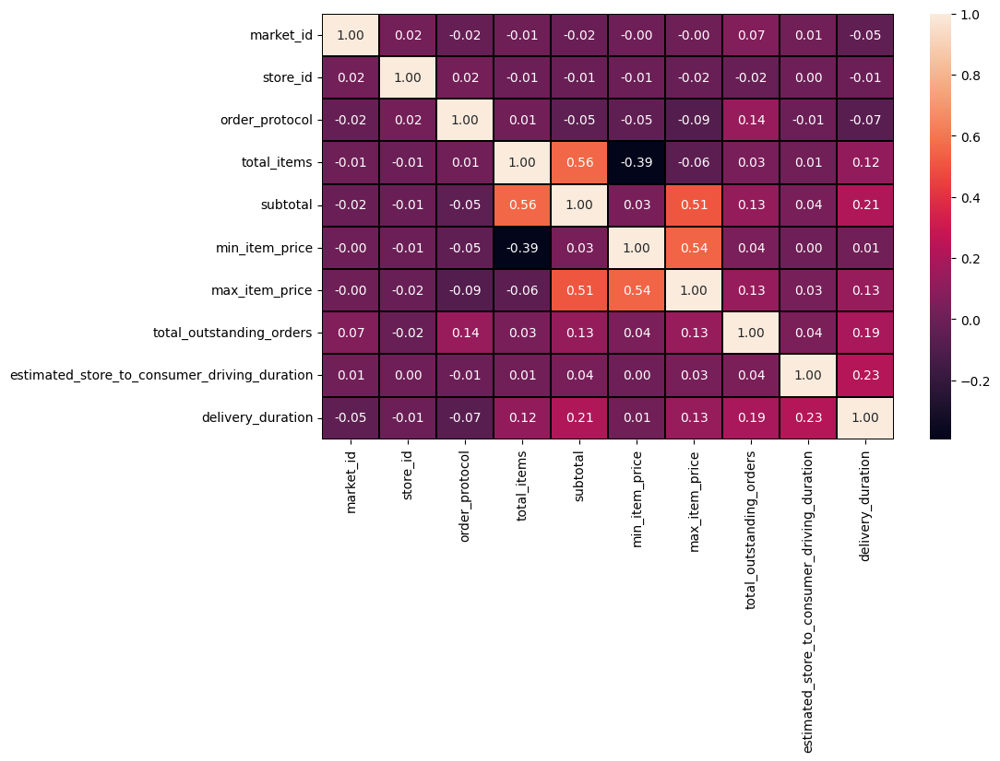

In [39]:
df_trim = df.drop(columns = ["estimated_order_place_duration", "num_distinct_items", "total_onshift_dashers", "total_busy_dashers"])

fig, ax = plt.subplots(figsize=(10, 6))

corr_plot = sns.heatmap(
              df_trim.corr(numeric_only=True),
              linewidths=0.1,
              linecolor='black',
              annot=True,
              fmt=".2f",
  )
display(corr_plot)

# Data Prep

In [40]:
# #encoding categorical variables
# from sklearn.preprocessing import OneHotEncoder
# ohe = OneHotEncoder(sparse_output=False, drop='if_binary', handle_unknown='ignore')

# df_encoded = ohe.fit_transform(df[["store_primary_category"]])
# df_encoded = pd.DataFrame(df_encoded, columns=ohe.get_feature_names_out(["store_primary_category"]))

# # Reset index so both DataFrames align correctly
# df_encoded = pd.concat([df_encoded, df.reset_index(drop=True)], axis=1)

df_new = df_trim.copy()

# creating new features from created_at column and dropping delivery time
df_new.drop(columns = 'actual_delivery_time', inplace=True)
df_new['year'] = df_new['created_at'].dt.year
df_new['month'] = df_new['created_at'].dt.month
df_new['week'] = df_new['created_at'].dt.isocalendar().week
df_new['day_of_week'] = df_new['created_at'].dt.day_of_week
df_new['hour'] = df_new['created_at'].dt.hour
df_new['minute'] = df_new['created_at'].dt.minute

df_new.drop(columns = ['created_at', 'store_primary_category'], inplace=True)
df_new.head()

,market_id,store_id,order_protocol,total_items,subtotal,min_item_price,max_item_price,total_outstanding_orders,estimated_store_to_consumer_driving_duration,delivery_duration,year,month,week,day_of_week,hour,minute
0,1.0,1845,1.0,4,3441,557,1239,21.0,861.0,3779.0,2015,2,6,4,22,24
1,2.0,5477,2.0,1,1900,1400,1400,2.0,690.0,4024.0,2015,2,7,1,21,49
2,3.0,5477,1.0,1,1900,1900,1900,0.0,690.0,1781.0,2015,1,4,3,20,39
3,3.0,5477,1.0,6,6900,600,1800,2.0,289.0,3075.0,2015,2,6,1,21,21
4,3.0,5477,1.0,3,3900,1100,1600,9.0,650.0,2390.0,2015,2,7,6,2,40


In [41]:
import sklearn
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df_new, test_size = 0.2)

x_train = df_train.drop(columns = ['delivery_duration'])
y_train = df_train['delivery_duration']

x_test = df_test.drop(columns = ['delivery_duration'])
y_test = df_test['delivery_duration']

print("Rows in training dataframe is", len(x_train))
print("Rows in testing dataframe is", len(x_test))

Rows in training dataframe is 153164
Rows in testing dataframe is 38292


# Model Fitting

## XGBoost

In [42]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Initialize model
model_xgb = XGBRegressor(
    objective='reg:squarederror',
    enable_categorical=True
)

# Fit model
model_xgb.fit(x_train, y_train)

# Predictions
xgb_train_pred = model_xgb.predict(x_train)
xgb_test_pred = model_xgb.predict(x_test)

# Evaluation
print("XGB Training RMSE: ", np.sqrt(mean_squared_error(y_train, xgb_train_pred)))
print("XGB Testing RMSE: ", np.sqrt(mean_squared_error(y_test, xgb_test_pred)))

print("XGB Training R2_Score: ", r2_score(y_train, xgb_train_pred))
print("XGB Testing R2_Score: ", r2_score(y_test, xgb_test_pred))

XGB Training RMSE:  847.4633253994525
XGB Testing RMSE:  969.5777049407262
XGB Training R2_Score:  0.4337754609248792
XGB Testing R2_Score:  0.29751259328635227


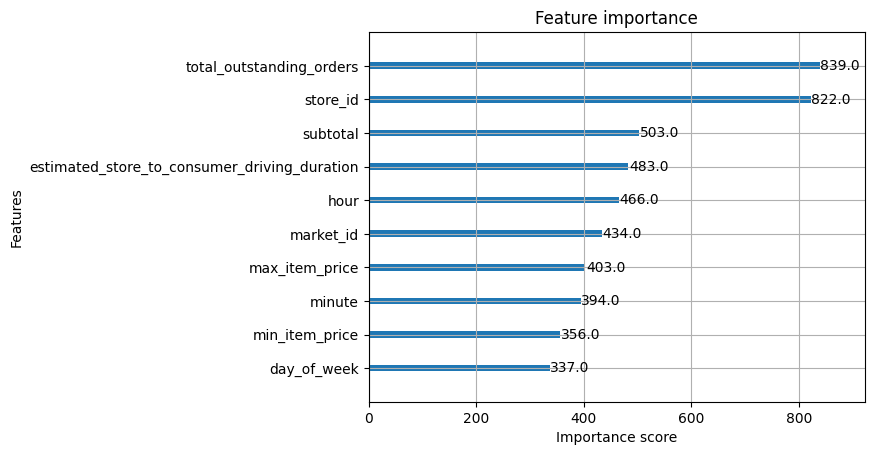

In [43]:
from xgboost import plot_importance
plot_importance(model_xgb, max_num_features=10)
plt.show()

## Light GBM

In [44]:
from lightgbm import LGBMRegressor

model_lgbm = LGBMRegressor(metric='rmse')
model_lgbm.fit(x_train, y_train)

lgbm_train_pred = model_lgbm.predict(x_train)
lgbm_test_pred = model_lgbm.predict(x_test)

print("LGBM Training RMSE: ", np.sqrt(mean_squared_error(y_train, lgbm_train_pred)))
print("LGBM Testing RMSE: ", np.sqrt(mean_squared_error(y_test, lgbm_test_pred)))

print("XGB Training R2_Score: ", r2_score(y_train, lgbm_train_pred))
print("XGB Testing R2_Score: ", r2_score(y_test, lgbm_test_pred))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000860 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1685
[LightGBM] [Info] Number of data points in the train set: 153164, number of used features: 14
[LightGBM] [Info] Start training from score 2855.263182
LGBM Training RMSE:  916.6113049637678
LGBM Testing RMSE:  975.4233237964089
XGB Training R2_Score:  0.3376046428312367
XGB Testing R2_Score:  0.289016414696057


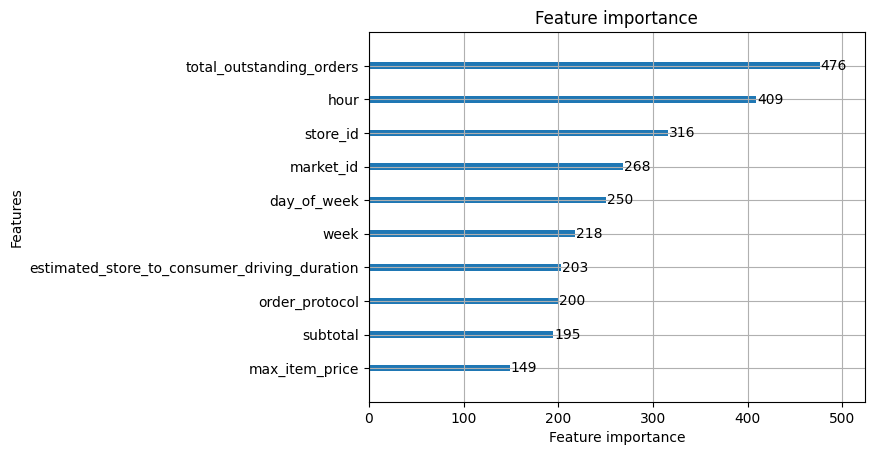

In [45]:
from lightgbm import plot_importance
plot_importance(model_lgbm, max_num_features=10)
plt.show()

## Grid Search CV

In [46]:
# from scipy.stats import randint, uniform
# from sklearn.model_selection import RandomizedSearchCV

# # Define parameter distributions
# param_dist = {
#     'n_estimators': randint(100, 600),          # random int between 100 and 600
#     'learning_rate': uniform(0.01, 0.09),       # between 0.01 and 0.1
#     'max_depth': randint(3, 10),                # between 3 and 9
#     'num_leaves': randint(20, 150),             # between 20 and 149
#     'min_child_samples': randint(10, 150),      # between 10 and 149
#     'subsample': uniform(0.7, 0.3),             # between 0.7 and 1.0
#     'colsample_bytree': uniform(0.7, 0.3),      # between 0.7 and 1.0
# }

# # Base model
# model_lgbm = LGBMRegressor(metric='rmse', random_state=42)

# # RandomizedSearchCV setup
# random_search = RandomizedSearchCV(
#     estimator=model_lgbm,
#     param_distributions=param_dist,
#     n_iter=50,                    # number of random combinations to try
#     scoring='neg_root_mean_squared_error',
#     cv=3,
#     n_jobs=-1,
#     verbose=2,
#     random_state=42
# )

# # Fit
# random_search.fit(x_train, y_train)

# # Best parameters and score
# print("Best Parameters:", random_search.best_params_)
# print("Best CV RMSE:", -random_search.best_score_)

# # Evaluate with best model
# best_model = random_search.best_estimator_

# lgbm_train_pred = best_model.predict(x_train)
# lgbm_test_pred = best_model.predict(x_test)

In [47]:
import shap
explainer = shap.TreeExplainer(model_lgbm)

# Use explainer() instead of explainer.shap_values()
shap_values = explainer(x_test)  # returns an Explanation object

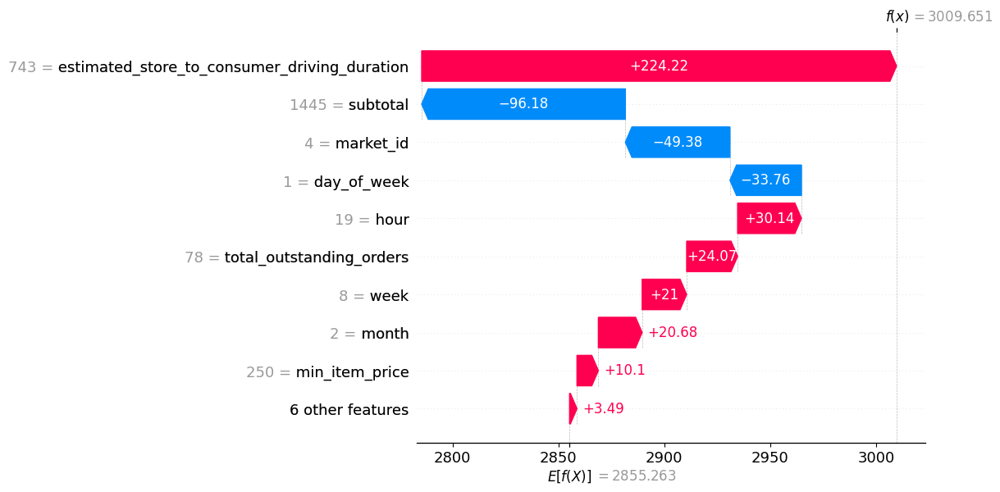

In [48]:
shap.plots.waterfall(shap_values[0])  # plot for the first test instance

In [49]:
shap.initjs()
shap.plots.force(shap_values[0:100])  # plot for the first 100 test instances

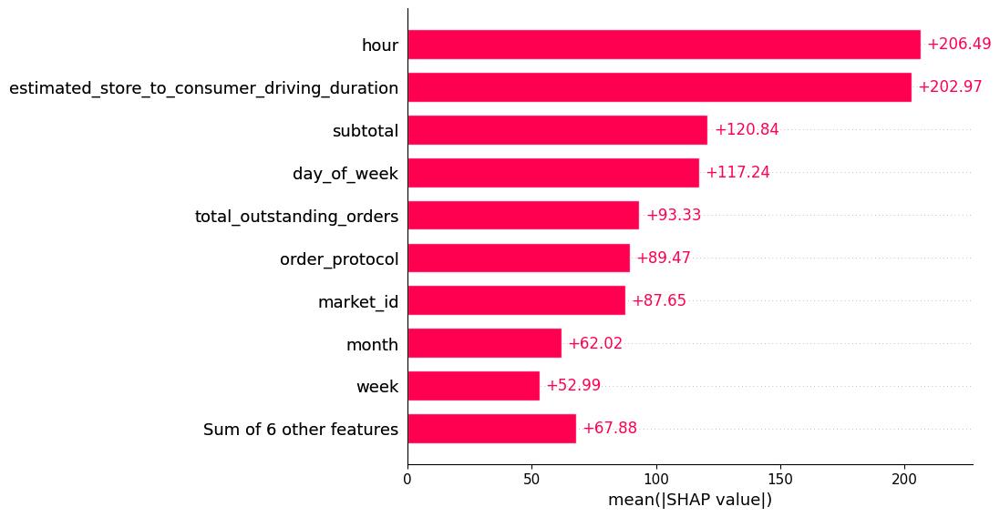

In [50]:
shap.plots.bar(shap_values)  

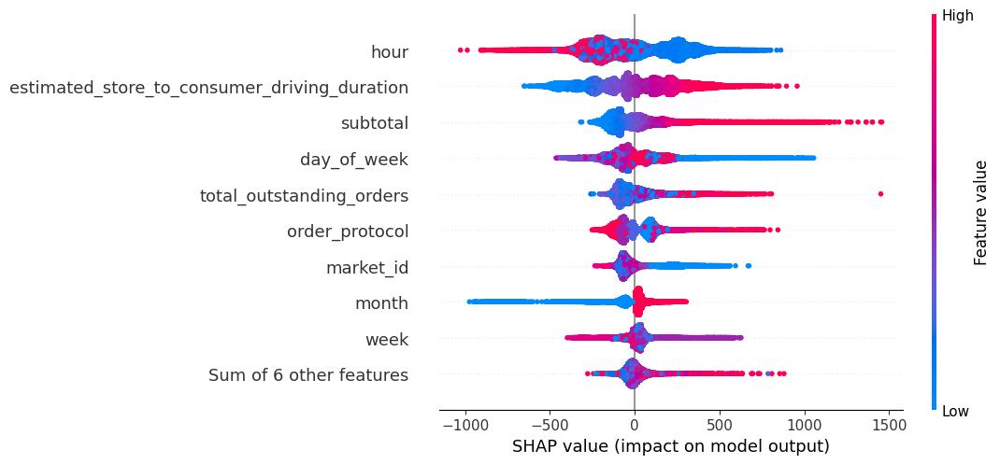

In [51]:
shap.plots.beeswarm(shap_values)

c:\Users\vijay\Documents\Git\stratascratch_doordash_delivery_times\.venv\Lib\site-packages\shap\plots\_scatter.py:452: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


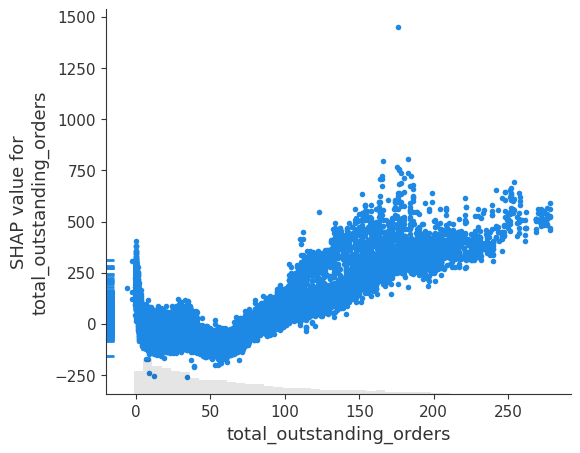

In [52]:
shap.plots.scatter(shap_values[:,"total_outstanding_orders"])